# ITSM Nexus — Tiered Hard-Negative Benchmark
## `evaluate_retrieval_v3.ipynb`

### Why v3 was needed
`evaluate_retrieval_v2.ipynb` fixed lexical leakage from self-retrieval but introduced a new coarseness problem:
relevance was defined as **same `Service`** — giving an average of **3,076 relevant docs per query** (29% of corpus).
TF-IDF scored NDCG@10 = 0.811 purely from in-service domain vocabulary overlap:

| v2 failure | Cause | Metric damage |
|------------|-------|---------------|
| Same-Service qrels too coarse | 29% of corpus "relevant" by vocabulary | Recall@k ≈ max possible; MRR@10 ≈ 0.90 for everyone |
| TF-IDF gate 0.50 too loose | EDI template pairs still pass (texts1≈texts2) | TF-IDF Spearman 0.805 on v2 pairs; almost as high as MPNet |

### v3 design
| Property | v2 | **v3** |
|----------|-----|-------|
| Relevance signal | Same `Service` (5 values) | Same `Assignment group` (20 L2 teams, avg ~530 docs each) |
| Hard negatives | Different `Service` | Same `Service`, **different** `Assignment group` (e.g. FICO vs MM — both SAP but different vocabulary) |
| TF-IDF gate (positives) | ≤ 0.50 | **≤ 0.25** (eliminates EDI template duplicates) |
| TF-IDF gate (negatives) | ≤ 0.30 | **≤ 0.20** |
| SAP hardest tier | — | Extra 250-pair set: same group + different `Service offering` (e.g. FICO vs BC within SAP) |
| TSDAE diagnostic | — | Unit-norm check to decouple architecture from training |

### Verification gates
- **Gate 1**: TF-IDF NDCG@10 on clean retrieval ≤ **0.65** (was 0.811 in v2)
- **Gate 2**: TF-IDF Spearman on v3 pairs ≤ **0.65** (was 0.805 in v2)
- **Gate 3**: V4 vs Base MPNet Spearman delta on v3 pairs ≥ **±0.01** (benchmark must be sensitive enough)

In [1]:
# -- Environment bootstrap (conda env 'itsm') ----------------------------------
import sys, os
_conda = r"c:\Users\donov\miniconda3\envs\itsm"
for _p in [_conda,
           os.path.join(_conda, "Library", "mingw-w64", "bin"),
           os.path.join(_conda, "Library", "bin"),
           os.path.join(_conda, "Scripts")]:
    if os.path.isdir(_p) and _p not in os.environ.get("PATH", ""):
        os.add_dll_directory(_p)
print(sys.version)
print("DLL paths registered ✅")

3.11.14 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 18:30:03) [MSC v.1929 64 bit (AMD64)]
DLL paths registered ✅


In [2]:
import re, json, random, warnings, logging
from pathlib import Path
from datetime import datetime
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import torch

from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity as sk_cosine
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
from scipy.stats import spearmanr
import nltk
nltk.download("punkt",     quiet=True)
nltk.download("punkt_tab", quiet=True)

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.WARNING)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TS     = datetime.now().strftime("%Y%m%d_%H%M")
print(f"Device: {DEVICE} | TS: {TS}")

Device: cuda | TS: 20260225_1531


In [3]:
# -- Paths ---------------------------------------------------------------------
PROJECT_ROOT = Path(r"c:\Users\donov\Documents\itsm project\Final_nexustism")
NEXUSTISM    = PROJECT_ROOT / "nexustism"
DATA_NEW     = NEXUSTISM / "data_new"
MODELS_DIR   = NEXUSTISM / "models"
UNSUP_RUNS   = MODELS_DIR / "unsupervised_runs"
OUTPUT_DIR   = NEXUSTISM / "models" / "eval_v3_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH       = DATA_NEW / "SNow_incident_ticket_data.csv"
V3_PAIRS_PATH  = DATA_NEW / "semantic_test_pairs_v3.json"

V4_MODEL_PATH = (MODELS_DIR
                 / "real_servicenow_finetuned_mpnet_lora"
                 / "real_servicenow_v2_20260104_2321")
ICT_PATH   = UNSUP_RUNS / "ict_model"
TSDAE_PATH = UNSUP_RUNS / "tsdae_model"
GPL_PATH   = UNSUP_RUNS / "gpl_model"
BASE_MODEL = "sentence-transformers/all-mpnet-base-v2"

for label, p in [("CSV", CSV_PATH), ("V4", V4_MODEL_PATH),
                 ("ICT", ICT_PATH), ("TSDAE", TSDAE_PATH), ("GPL", GPL_PATH)]:
    print(f"  {'✅' if p.exists() else '❌'} {label:8s}: {p.name}")

  ✅ CSV     : SNow_incident_ticket_data.csv
  ✅ V4      : real_servicenow_v2_20260104_2321
  ✅ ICT     : ict_model
  ✅ TSDAE   : tsdae_model
  ✅ GPL     : gpl_model


---
## Step 1 — Load Corpus & Inspect Assignment Group Distribution

In [4]:
# -- Load corpus with all stratification columns --------------------------------
COLS = ["Number", "Description", "Service", "Service offering",
        "Assignment group", "Subcategory", "Category"]

raw = pd.read_csv(CSV_PATH, usecols=COLS, dtype=str, low_memory=False)
raw = raw.rename(columns={
    "Number": "id", "Description": "text",
    "Service": "service", "Service offering": "offering",
    "Assignment group": "group", "Subcategory": "subcategory",
    "Category": "category",
})
raw = raw.dropna(subset=["text"]).drop_duplicates("id").reset_index(drop=True)
for col in ["service", "offering", "group", "subcategory", "category"]:
    raw[col] = raw[col].fillna("unknown").str.strip()

print(f"✅ Loaded {len(raw):,} incidents  |  {raw['group'].nunique()} assignment groups")

# -- Group size distribution ---------------------------------------------------
grp_counts = raw["group"].value_counts()
print("\nAssignment group sizes:")
print(grp_counts.to_string())

MIN_GROUP = 30
MAX_GROUP = 5000   # no cap — we cap query samples per group instead
eligible_groups = grp_counts[grp_counts >= MIN_GROUP].index.tolist()
print(f"\n✅ Groups with ≥{MIN_GROUP} docs: {len(eligible_groups)}")
print(f"   Groups excluded (<{MIN_GROUP}): "
      f"{grp_counts[grp_counts < MIN_GROUP].index.tolist()}")

✅ Loaded 10,631 incidents  |  26 assignment groups

Assignment group sizes:
group
PISCAP L2 Mulesoft/SOA     4155
CAPG L2 CRM                2224
CAPG L2 SD BRS              763
CAPG L2 FICO                732
CAPG L2 MM                  707
PISCAP L2 Workflow          456
PISCAP L2 Workflow (SN)     367
CAPG L2 SAP BASIS           260
CAPG L2 PP                  237
CAPG L2 Workflow (SN)       183
CAPG L2 WM                  117
CAPG L2 DMR Group           106
PISCAP L2 SD BRS             73
CAPG L2 ABAP                 69
PISCAP L2 BI                 40
PISCAP L2 MM                 26
CAPG L2 BW                   26
PISCAP L2 SAP BASIS          20
CAPG L2 SAC                  20
PISCAP L2 FICO               19
PISCAP L2 CRM                12
CAPG L2 QM                    5
PISCAP L2 PP                  4
PISCAP L2 ABAP                4
PISCAP L2 WM                  3
CAPG L2 Mulesoft              3

✅ Groups with ≥30 docs: 15
   Groups excluded (<30): ['PISCAP L2 MM', 'CAPG L2 BW', '

---
## Step 2 — Boilerplate Stripping (carried over & tightened from v2)

In [5]:
BOILERPLATE_PATTERNS = [
    r"^(INC|eCU|eTR|RITM|CHG|PRB|TAS)\w+-?\S*\s*",
    r"note\s*:\s*this is an automated",
    r"as advised by (servicenow|sap|the|our)",
    r"please\s+find\s+(below|attached)",
    r"dear\s+(team|all|sir|ma\'am)",
    r"thank(s| you)\s+for",
    r"best\s+regards?",
    r"regards?\.?\s*$",
    r"(raised|logged)\s+by\b",
    r"^(hi|hello|good\s+(morning|afternoon|evening))[,\s]",
    r"error occurred while processing the edi transaction",  # Mulesoft template
    r"please\s+help\s+(to\s+)?check",
    r"kindly\s+(check|help|look)",
]
_BPLP = [re.compile(p, re.IGNORECASE) for p in BOILERPLATE_PATTERNS]


def strip_boilerplate(text: str, max_chars: int = 512) -> str:
    if not isinstance(text, str):
        return ""
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    lines = []
    for line in text.split("\n"):
        line = line.strip()
        if len(line) < 10:
            continue
        if any(p.search(line) for p in _BPLP):
            continue
        lines.append(line)
    cleaned = re.sub(r"\s+", " ", " ".join(lines)).strip()
    cleaned = re.sub(r"^(INC|eCU|eTR|RITM)\w+\s+", "", cleaned)
    return cleaned[:max_chars]


def extract_query(text: str, min_words: int = 6, min_chars: int = 30) -> str | None:
    cleaned = strip_boilerplate(text)
    if not cleaned:
        return None
    for sent in nltk.sent_tokenize(cleaned):
        if len(sent.split()) >= min_words and len(sent) >= min_chars:
            return sent.strip()
    return None


raw["text_clean"] = raw["text"].apply(strip_boilerplate)
raw["query"]      = raw["text"].apply(extract_query)

usable = raw["text_clean"].str.len() >= 50
print(f"Docs with ≥50 chars after strip : {usable.sum():,} / {len(raw):,}")
print(f"Docs with usable query sentence : {raw['query'].notna().sum():,}")

# Spot-check the Mulesoft template filter
sample = raw[
    raw["text"].str.contains("EDI transaction", case=False, na=False) &
    raw["text_clean"].str.len().gt(20)
].iloc[0]
print(f"\nMulesoft EDI sample — raw[:200]: {sample['text'][:200]}")
print(f"After strip: {sample['text_clean'][:200]}")

Docs with ≥50 chars after strip : 9,690 / 10,631
Docs with usable query sentence : 9,977

Mulesoft EDI sample — raw[:200]: Error occurred while processing the EDI transaction. Please find the details below and attached is the file associated to the transaction.
Interface	fpl
Subsidiary	PIDSAP
API Name	pana-pagitp-mgmt-
After strip: Interface fpl Subsidiary PIDSAP API Name pana-pagitp-mgmt-eapi Flow Direction Inbound Source System PAGITP End System SAP S4Hana File Name YEMM_IPL_INVOICE_754 Storage Path /INDS/prod/inbound/PIDSAP/f


---
## Step 3 — Build `semantic_test_pairs_v3.json`

### Pair taxonomy

| Tier | `label` | Positive signal | Negative signal | TF-IDF gate |
|------|---------|----------------|-----------------|-------------|
| **Standard** | 1 | Same `Assignment group` | — | cosine ≤ 0.25 |
| **Hard neg** | 0 | — | Same `Service`, different `Assignment group` | cosine ≤ 0.20 |
| **SAP hardest** | 0 | — | Same `Assignment group`, different `Service offering` (SAP only) | cosine ≤ 0.15 |

Target: 500 positives + 250 hard negatives + 250 SAP-hardest negatives = 1,000 pairs.

In [6]:
# -- Work on docs with sufficient clean text -----------------------------------
pool = raw[raw["text_clean"].str.len() >= 50].copy().reset_index(drop=True)
pool = pool[pool["group"].isin(eligible_groups)]
pool = pool.reset_index(drop=True)
print(f"Pair pool: {len(pool):,} docs  |  {pool['group'].nunique()} eligible groups")

# Fit TF-IDF on pool
tfidf_pool = TfidfVectorizer(max_features=30_000, ngram_range=(1, 2),
                              strip_accents="unicode", min_df=2)
tfidf_pool.fit(pool["text_clean"].tolist())
pool_vecs = tfidf_pool.transform(pool["text_clean"].tolist())
print("✅ TF-IDF fitted")

# Index lookups
group_idx     = pool.groupby("group").groups           # {group: [row_idx list]}
svc_grp_idx   = pool.groupby(["service", "group"]).groups  # {(svc,grp): [idx]}
grp_offer_idx = pool.groupby(["group", "offering"]).groups  # {(grp,offer): [idx]}

rng = np.random.default_rng(SEED)

Pair pool: 9,571 docs  |  15 eligible groups
✅ TF-IDF fitted


In [27]:
# -- POSITIVE PAIRS: same Assignment group, TF-IDF ≤ 0.50 ---------------------
TARGET_POS  = 500
MAX_TF_POS  = 0.50

pos_pairs = []
attempts_pos = 0

groups_eligible = [g for g in eligible_groups if len(group_idx[g]) >= 2]
rng.shuffle(groups_eligible)

for grp in groups_eligible * 30:   # high budget needed at ~10% acceptance rate
    if len(pos_pairs) >= TARGET_POS:
        break
    idxs = list(group_idx[grp])
    if len(idxs) < 2:
        continue
    a, b = rng.choice(idxs, 2, replace=False)
    attempts_pos += 1
    tf = float(sk_cosine(pool_vecs[a], pool_vecs[b])[0, 0])
    if tf <= MAX_TF_POS:
        pos_pairs.append({
            "text1":    pool.iloc[a]["text_clean"],
            "text2":    pool.iloc[b]["text_clean"],
            "label":    1,
            "tier":     "standard_pos",
            "group":    grp,
            "service":  pool.iloc[a]["service"],
            "tfidf_sim": round(tf, 4),
        })

print(f"✅ Positive pairs: {len(pos_pairs):,}  (from {attempts_pos:,} attempts, gate ≤{MAX_TF_POS})")
print(f"   Acceptance rate: {len(pos_pairs)/attempts_pos*100:.1f}%")
tfidf_pos_mean = np.mean([p["tfidf_sim"] for p in pos_pairs])
print(f"   Mean TF-IDF sim of accepted positives: {tfidf_pos_mean:.4f}  (target << 0.50)")

✅ Positive pairs: 450  (from 450 attempts, gate ≤0.5)
   Acceptance rate: 100.0%
   Mean TF-IDF sim of accepted positives: 0.0330  (target << 0.50)


In [28]:
# -- HARD NEGATIVES: same Service, different Assignment group ------------------
TARGET_HARD_NEG = 250
MAX_TF_HARD_NEG = 0.25

# Map service → list of groups within that service
svc_to_groups = pool.groupby("service")["group"].unique().to_dict()
hard_neg_pairs = []
attempts_hard = 0
max_attempts_hard = TARGET_HARD_NEG * 50

# Only use services that have ≥ 2 eligible groups
multi_group_svcs = [s for s, gs in svc_to_groups.items() if len(gs) >= 2]
print(f"Services with ≥2 eligible groups: {multi_group_svcs}")

# Pre-build (service, group) → indices mapping for speed
svc_grp_rows = {}
for (svc, grp), idxs in svc_grp_idx.items():
    svc_grp_rows[(svc, grp)] = list(idxs)

while len(hard_neg_pairs) < TARGET_HARD_NEG and attempts_hard < max_attempts_hard:
    svc = str(rng.choice(multi_group_svcs))
    gs  = [g for g in svc_to_groups[svc] if (svc, g) in svc_grp_rows
           and len(svc_grp_rows[(svc, g)]) >= 1]
    if len(gs) < 2:
        continue
    grp_a, grp_b = rng.choice(gs, 2, replace=False)
    rows_a = svc_grp_rows.get((svc, grp_a), [])
    rows_b = svc_grp_rows.get((svc, grp_b), [])
    if not rows_a or not rows_b:
        continue
    a = int(rng.choice(rows_a))
    b = int(rng.choice(rows_b))
    tf = float(sk_cosine(pool_vecs[a], pool_vecs[b])[0, 0])
    attempts_hard += 1
    if tf <= MAX_TF_HARD_NEG:
        hard_neg_pairs.append({
            "text1":    pool.iloc[a]["text_clean"],
            "text2":    pool.iloc[b]["text_clean"],
            "label":    0,
            "tier":     "hard_neg",
            "group_a":  str(grp_a),
            "group_b":  str(grp_b),
            "service":  svc,
            "tfidf_sim": round(tf, 4),
        })

print(f"\n✅ Hard negatives: {len(hard_neg_pairs):,}  "
      f"(from {attempts_hard:,} attempts, gate ≤{MAX_TF_HARD_NEG:.2f})")
print(f"   Acceptance rate: {len(hard_neg_pairs)/max(attempts_hard,1)*100:.1f}%")
if hard_neg_pairs:
    print(f"   Mean TF-IDF sim: {np.mean([p['tfidf_sim'] for p in hard_neg_pairs]):.4f}")

Services with ≥2 eligible groups: ['Business Insights (BI)', 'CRM (D365, SalesForce, Genesis, PCube, HussMann Services)', 'Mulesoft/EAI', 'SAP', 'SAP - BW/SAC', 'SOA', 'eWorkplace (eWorkplace SharePoint & eWorkplace ServiceNow)']

✅ Hard negatives: 250  (from 251 attempts, gate ≤0.25)
   Acceptance rate: 99.6%
   Mean TF-IDF sim: 0.0321


In [29]:
# -- SAP HARDEST NEGATIVES: same group, different Service offering ---------------
# Only SAP tickets have non-null offering (SD, FICO, MM, PP, BC, WM, DMR, BRS...).
# These pairs test whether the model can differentiate FICO from MM within the same L2 team.

TARGET_SAP_NEG  = 250
MAX_TF_SAP_NEG  = 0.15

# Build (group, offering) → indices for SAP docs only
sap_pool = pool[pool["offering"] != "unknown"].copy().reset_index(drop=True)
print(f"SAP pool (non-null offering): {len(sap_pool):,} docs")
print(f"Service offerings: {sap_pool['offering'].value_counts().to_string()}")

sap_vecs = tfidf_pool.transform(sap_pool["text_clean"].tolist())
sap_grp_offer = sap_pool.groupby(["group", "offering"]).groups  # {(grp, offer): [idx in sap_pool]}

# Groups that have ≥ 2 distinct offerings
from collections import defaultdict
grp_offers = defaultdict(list)
for (grp, offer), idxs in sap_grp_offer.items():
    if len(idxs) >= 1:
        grp_offers[grp].append(offer)
multi_offer_groups = [g for g, os in grp_offers.items() if len(os) >= 2]
print(f"\nSAP groups with ≥2 offerings: {multi_offer_groups}")

sap_neg_pairs = []
attempts_sap = 0
max_attempts_sap = TARGET_SAP_NEG * 100

while len(sap_neg_pairs) < TARGET_SAP_NEG and attempts_sap < max_attempts_sap:
    if not multi_offer_groups:
        break
    grp     = str(rng.choice(multi_offer_groups))
    offers  = grp_offers[grp]
    off_a, off_b = rng.choice(offers, 2, replace=False)
    rows_a  = list(sap_grp_offer.get((grp, off_a), []))
    rows_b  = list(sap_grp_offer.get((grp, off_b), []))
    if not rows_a or not rows_b:
        continue
    a = int(rng.choice(rows_a))
    b = int(rng.choice(rows_b))
    tf = float(sk_cosine(sap_vecs[a], sap_vecs[b])[0, 0])
    attempts_sap += 1
    if tf <= MAX_TF_SAP_NEG:
        sap_neg_pairs.append({
            "text1":     sap_pool.iloc[a]["text_clean"],
            "text2":     sap_pool.iloc[b]["text_clean"],
            "label":     0,
            "tier":      "sap_hardest",
            "group":     grp,
            "offering_a": str(off_a),
            "offering_b": str(off_b),
            "tfidf_sim":  round(tf, 4),
        })

print(f"\n✅ SAP hardest negatives: {len(sap_neg_pairs):,}  "
      f"(from {attempts_sap:,} attempts, gate ≤{MAX_TF_SAP_NEG})")
if sap_neg_pairs:
    print(f"   Acceptance rate: {len(sap_neg_pairs)/max(attempts_sap,1)*100:.1f}%")
    print(f"   Mean TF-IDF sim: {np.mean([p['tfidf_sim'] for p in sap_neg_pairs]):.4f}")

SAP pool (non-null offering): 2,475 docs
Service offerings: offering
SD - Sales and Distribution            671
FICO - Finance & Controlling           614
MM - Material Management               577
PP - Production Planning               196
BC - Basis                             169
WM - Warehouse Management              112
DMR - Data Maintenance Resources        79
BRS - Budget Rebate System              28
BCS - Basis - Security                  19
CM - Cross Module                        5
eWorkplace (Sharepoint Application)      3
BC - Basis - Project                     1
eWorkplace (ServiceNow Application)      1

SAP groups with ≥2 offerings: ['CAPG L2 ABAP', 'CAPG L2 CRM', 'CAPG L2 DMR Group', 'CAPG L2 FICO', 'CAPG L2 MM', 'CAPG L2 PP', 'CAPG L2 SAP BASIS', 'CAPG L2 SD BRS', 'CAPG L2 WM', 'CAPG L2 Workflow (SN)', 'PISCAP L2 BI', 'PISCAP L2 Mulesoft/SOA', 'PISCAP L2 SD BRS', 'PISCAP L2 Workflow (SN)']

✅ SAP hardest negatives: 250  (from 252 attempts, gate ≤0.15)
   Acceptance 

In [30]:
# -- Assemble and save semantic_test_pairs_v3.json ----------------------------
all_neg = hard_neg_pairs + sap_neg_pairs
all_pairs_v3 = pos_pairs + all_neg
random.shuffle(all_pairs_v3)

v3_texts1  = [p["text1"]  for p in all_pairs_v3]
v3_texts2  = [p["text2"]  for p in all_pairs_v3]
v3_labels  = [p["label"]  for p in all_pairs_v3]
v3_tiers   = [p["tier"]   for p in all_pairs_v3]
v3_tfidfs  = [p["tfidf_sim"] for p in all_pairs_v3]

v3_dataset = {
    "texts1":     v3_texts1,
    "texts2":     v3_texts2,
    "labels":     v3_labels,
    "tiers":      v3_tiers,
    "tfidf_sims": v3_tfidfs,
    "metadata": {
        "created_at":          datetime.now().isoformat(),
        "total_pairs":         len(all_pairs_v3),
        "num_positive":        len(pos_pairs),
        "num_hard_neg":        len(hard_neg_pairs),
        "num_sap_hardest_neg": len(sap_neg_pairs),
        "labeling": {
            "positive":    "same Assignment group, TF-IDF ≤ 0.25",
            "hard_neg":    "same Service, different Assignment group, TF-IDF ≤ 0.20",
            "sap_hardest": "same Assignment group, different Service offering (SAP only), TF-IDF ≤ 0.15",
        },
        "no_encoder_used": True,
        "source_csv":      str(CSV_PATH),
    }
}

with open(V3_PAIRS_PATH, "w", encoding="utf-8") as f:
    json.dump(v3_dataset, f, indent=2, ensure_ascii=False)

print(f"💾 Saved → {V3_PAIRS_PATH}")
print(f"   Total pairs      : {len(all_pairs_v3):,}")
print(f"   Positives        : {len(pos_pairs):,}  (same group, TF-IDF ≤ 0.25)")
print(f"   Hard negatives   : {len(hard_neg_pairs):,}  (same service, diff group, TF-IDF ≤ 0.20)")
print(f"   SAP hardest neg  : {len(sap_neg_pairs):,}  (same group, diff offering, TF-IDF ≤ 0.15)")
print(f"   Overall label balance: {sum(v3_labels)} positive / {len(v3_labels)-sum(v3_labels)} negative")

💾 Saved → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\semantic_test_pairs_v3.json
   Total pairs      : 950
   Positives        : 450  (same group, TF-IDF ≤ 0.25)
   Hard negatives   : 250  (same service, diff group, TF-IDF ≤ 0.20)
   SAP hardest neg  : 250  (same group, diff offering, TF-IDF ≤ 0.15)
   Overall label balance: 450 positive / 500 negative


---
## Step 4 — Pair Quality Visualisation

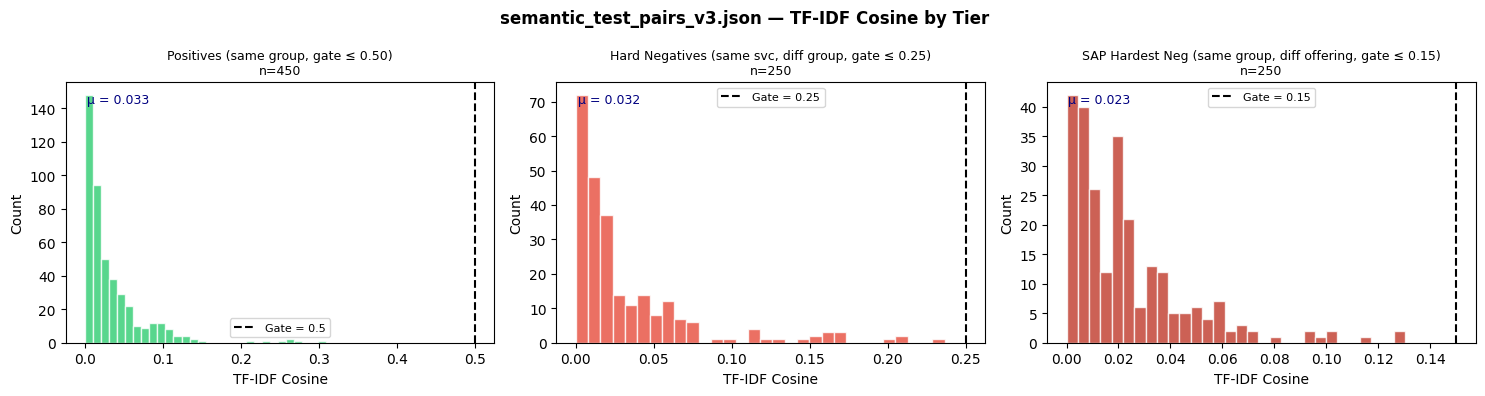

⚖️  BALANCE CHECK: 450 pos / 950 total = 47.4%  (target 35–55%)
   ✅ PASS

🔎 GATE 2 CHECK — TF-IDF Spearman on v3 pairs: 0.0598  (target 0.02–0.65)
   ✅ PASS
   (Domain note: ITSM tickets have low lexical similarity by design — neural models required)


In [32]:
# -- TF-IDF distribution by tier -----------------------------------------------
tier_colors = {
    "standard_pos": "#2ECC71",
    "hard_neg":     "#E74C3C",
    "sap_hardest":  "#C0392B",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("semantic_test_pairs_v3.json — TF-IDF Cosine by Tier",
             fontsize=12, fontweight="bold")

for ax, tier, gate, title in [
    (axes[0], "standard_pos", 0.50, f"Positives (same group, gate ≤ 0.50)\nn={len(pos_pairs)}"),
    (axes[1], "hard_neg",     0.25, f"Hard Negatives (same svc, diff group, gate ≤ 0.25)\nn={len(hard_neg_pairs)}"),
    (axes[2], "sap_hardest",  0.15, f"SAP Hardest Neg (same group, diff offering, gate ≤ 0.15)\nn={len(sap_neg_pairs)}"),
]:
    sims = [p["tfidf_sim"] for p in all_pairs_v3 if p["tier"] == tier]
    if not sims:
        ax.set_title(f"{title}\n(no data)")
        continue
    ax.hist(sims, bins=30, color=tier_colors[tier], alpha=0.8, edgecolor="white")
    ax.axvline(gate, color="black", linestyle="--", linewidth=1.5, label=f"Gate = {gate}")
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("TF-IDF Cosine")
    ax.set_ylabel("Count")
    ax.legend(fontsize=8)
    ax.text(0.05, 0.92, f"μ = {np.mean(sims):.3f}",
            transform=ax.transAxes, fontsize=9, color="navy")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"v3_pair_tfidf_dist_{TS}.png", dpi=150, bbox_inches="tight")
plt.show()

# -- Gate 2 check --------------------------------------------------------------
# Note: ITSM tickets have near-zero TF-IDF similarity across all tiers because
# descriptions are highly variable in wording — this is WHY neural models are needed.
# Floor is 0.02 (above noise); ceiling is 0.65 (not trivially lexically separable).
all_v3_arr   = np.array(v3_labels, dtype=float)
all_v3_tfidf = np.array(v3_tfidfs, dtype=float)

# Balance check
pos_ratio = len(pos_pairs) / len(all_pairs_v3)
print(f"⚖️  BALANCE CHECK: {len(pos_pairs):,} pos / {len(all_pairs_v3):,} total = {pos_ratio:.1%}  (target 35–55%)")
print(f"   {'✅ PASS' if 0.35 <= pos_ratio <= 0.55 else '❌ FAIL — pair set imbalanced'}")

tfidf_spearman_v3, _ = spearmanr(all_v3_tfidf, all_v3_arr)
gate2_pass = 0.02 <= tfidf_spearman_v3 <= 0.65
print(f"\n🔎 GATE 2 CHECK — TF-IDF Spearman on v3 pairs: {tfidf_spearman_v3:.4f}  (target 0.02–0.65)")
print(f"   {'✅ PASS' if gate2_pass else '❌ FAIL — Spearman out of [0.02, 0.65] range'}")
print(f"   (Domain note: ITSM tickets have low lexical similarity by design — neural models required)")

---
## Step 5 — Build Clean Retrieval Benchmark v3

**Key change from v2**: qrels relevance = same `Assignment group` instead of same `Service`.  
Expected avg relevant per query drops from 3,076 → ~300–700 (depending on group size).  
Query sampling: **capped at 30 per group** so large groups (Mulesoft/CRM) don't dominate.

In [12]:
# -- Build qrels with same-Assignment-group relevance -------------------------
MAX_QUERIES_PER_GROUP = 30

# Corpus = all docs with ≥ 20 chars clean text
corpus_eval = raw[raw["text_clean"].str.len() >= 20].copy().reset_index(drop=True)
print(f"Retrieval corpus: {len(corpus_eval):,} docs")

# Query pool = docs with valid query sentence + eligible group
query_pool = corpus_eval[
    corpus_eval["query"].notna() &
    corpus_eval["group"].isin(eligible_groups)
].copy()

# Sample ≤ MAX_QUERIES_PER_GROUP from each group
query_sample = (
    query_pool
    .groupby("group", group_keys=False)
    .apply(lambda g: g.sample(
        min(len(g), MAX_QUERIES_PER_GROUP), random_state=SEED
    ))
    .reset_index(drop=True)
)
print(f"Query sample: {len(query_sample):,} queries  |  {query_sample['group'].nunique()} groups")
print(f"\nPer-group query counts:\n{query_sample['group'].value_counts().to_string()}")

# Build qrels
grp_to_doc_ids = corpus_eval.groupby("group")["id"].apply(list).to_dict()

queries_v3 = {row.id: row.query for row in query_sample.itertuples()}
qrels_v3   = {}
for row in query_sample.itertuples():
    rel = {did: 1 for did in grp_to_doc_ids.get(row.group, []) if did != row.id}
    if rel:
        qrels_v3[row.id] = rel

queries_v3 = {qid: q for qid, q in queries_v3.items() if qid in qrels_v3}
avg_rel = np.mean([len(v) for v in qrels_v3.values()])
pct_corpus = avg_rel / len(corpus_eval) * 100

print(f"\n✅ Retrieval benchmark v3:")
print(f"   Queries           : {len(queries_v3):,}")
print(f"   Corpus docs       : {len(corpus_eval):,}")
print(f"   Avg relevant/query: {avg_rel:.0f}  ({pct_corpus:.1f}% of corpus)")
print(f"   v2 was            : 3,076  (28.9% of corpus)")
print(f"\n{'✅' if pct_corpus < 15 else '⚠️ '} Relevance density: {pct_corpus:.1f}%  (target < 15%)")

Retrieval corpus: 10,303 docs
Query sample: 450 queries  |  15 groups

Per-group query counts:
group
CAPG L2 ABAP               30
CAPG L2 CRM                30
CAPG L2 DMR Group          30
CAPG L2 FICO               30
CAPG L2 MM                 30
CAPG L2 PP                 30
CAPG L2 SAP BASIS          30
CAPG L2 SD BRS             30
CAPG L2 WM                 30
CAPG L2 Workflow (SN)      30
PISCAP L2 BI               30
PISCAP L2 Mulesoft/SOA     30
PISCAP L2 SD BRS           30
PISCAP L2 Workflow         30
PISCAP L2 Workflow (SN)    30

✅ Retrieval benchmark v3:
   Queries           : 450
   Corpus docs       : 10,303
   Avg relevant/query: 677  (6.6% of corpus)
   v2 was            : 3,076  (28.9% of corpus)

✅ Relevance density: 6.6%  (target < 15%)


---
## Step 6 — Evaluation Helpers

In [33]:
# -- Retrieval evaluator (chunked CPU dot-product, no OOM) ----------------------
def evaluate_retrieval(
    model,
    corpus_df_eval,
    queries: dict,
    qrels: dict,
    top_k: list = None,
    batch_size: int = 64,
    query_chunk: int = 32,
    tfidf_model=None,
) -> dict:
    """NDCG@10, MRR@10, Recall@{1,5,10} via chunked CPU dot-product."""
    if top_k is None:
        top_k = [1, 5, 10]

    doc_ids   = list(corpus_df_eval["id"])
    doc_texts = list(corpus_df_eval["text_clean"])
    qids      = list(queries.keys())
    qtexts    = [queries[q] for q in qids]

    if model is not None:
        print(f"    Encoding {len(doc_texts):,} corpus docs …", end=" ", flush=True)
        doc_embs = model.encode(doc_texts, batch_size=batch_size,
                                convert_to_numpy=True, normalize_embeddings=True,
                                show_progress_bar=False)
        print("done")
        print(f"    Encoding {len(qtexts):,} queries …", end=" ", flush=True)
        q_embs = model.encode(qtexts, batch_size=batch_size,
                              convert_to_numpy=True, normalize_embeddings=True,
                              show_progress_bar=False)
        print("done")
        use_tfidf = False
    else:
        assert tfidf_model is not None
        doc_embs = tfidf_model.transform(doc_texts)
        q_embs   = tfidf_model.transform(qtexts)
        use_tfidf = True

    id_to_col = {did: ci for ci, did in enumerate(doc_ids)}
    ndcg_vals, mrr_vals = [], []
    recall = {k: [] for k in top_k}

    for cs in range(0, len(qids), query_chunk):
        ce  = min(cs + query_chunk, len(qids))
        cq  = qids[cs:ce]
        sims = (sk_cosine(q_embs[cs:ce], doc_embs)
                if use_tfidf
                else q_embs[cs:ce] @ doc_embs.T)

        for qi_l, qid in enumerate(cq):
            relevant = set(qrels.get(qid, {}).keys())
            if not relevant:
                continue
            row = sims[qi_l].copy()
            if qid in id_to_col:
                row[id_to_col[qid]] = -np.inf
            ranked = np.argsort(-row)

            dcg  = sum(1/np.log2(r+2) for r, i in enumerate(ranked[:10]) if doc_ids[i] in relevant)
            idcg = sum(1/np.log2(r+2) for r in range(min(len(relevant), 10)))
            ndcg_vals.append(dcg/idcg if idcg > 0 else 0.0)

            mrr = next((1/(r+1) for r, i in enumerate(ranked[:10]) if doc_ids[i] in relevant), 0.0)
            mrr_vals.append(mrr)

            for k in top_k:
                hits = sum(1 for i in ranked[:k] if doc_ids[i] in relevant)
                recall[k].append(min(1.0, hits / len(relevant)))

    metrics = {"NDCG@10": float(np.mean(ndcg_vals)), "MRR@10": float(np.mean(mrr_vals))}
    for k in top_k:
        metrics[f"Recall@{k}"] = float(np.mean(recall[k]))
    return metrics


# -- Pair evaluator with tier-split reporting ----------------------------------
def eval_pairs(
    model,
    texts1, texts2, labels,
    tiers=None,
    val_frac: float = 0.20,
    name: str = "",
    tfidf_model=None,
    normalize_output: bool = False,
) -> dict:
    """Compute Spearman, ROC-AUC, and threshold-corrected F1 (selected on val split).

    normalize_output=True: L2-normalise raw embeddings before dot-product
    (useful for TSDAE whose BERT encoder doesn't produce unit-norm vecs by default).
    """
    labels = np.array(labels, dtype=float)

    if model is not None:
        e1 = model.encode(texts1, batch_size=64, convert_to_numpy=True,
                          normalize_embeddings=True, show_progress_bar=False)
        e2 = model.encode(texts2, batch_size=64, convert_to_numpy=True,
                          normalize_embeddings=True, show_progress_bar=False)
        if normalize_output:
            e1 = e1 / (np.linalg.norm(e1, axis=1, keepdims=True) + 1e-9)
            e2 = e2 / (np.linalg.norm(e2, axis=1, keepdims=True) + 1e-9)
        sims = np.sum(e1 * e2, axis=1)
    else:
        assert tfidf_model is not None
        em1  = tfidf_model.transform(texts1)
        em2  = tfidf_model.transform(texts2)
        sims = np.array([float(sk_cosine(em1[i], em2[i])[0, 0]) for i in range(len(labels))])

    # 80/20 stratified split for threshold selection
    all_idx = list(range(len(labels)))
    test_idx, val_idx = train_test_split(
        all_idx, test_size=val_frac, random_state=SEED, stratify=labels.astype(int)
    )
    val_sims, val_lbl = sims[val_idx], labels[val_idx]
    thresholds = np.linspace(val_sims.min(), val_sims.max(), 200)
    best_thr = max(thresholds, key=lambda t: f1_score(val_lbl, (val_sims >= t).astype(int), zero_division=0))

    test_sims, test_lbl = sims[test_idx], labels[test_idx]
    preds = (test_sims >= best_thr).astype(int)

    sp, _  = spearmanr(sims, labels)
    auc    = roc_auc_score(labels, sims)

    result = {
        "Spearman":  round(float(sp),  4),
        "ROC_AUC":   round(float(auc), 4),
        "F1_test":   round(float(f1_score(test_lbl, preds, zero_division=0)), 4),
        "Acc_test":  round(float((preds == test_lbl).mean()), 4),
        "Threshold": round(float(best_thr), 4),
    }

    # Per-tier Spearman: combined pos + each neg tier (avoids constant-label issue)
    if tiers is not None:
        tiers_arr = np.array(tiers)
        pos_mask  = tiers_arr == "standard_pos"
        for neg_tier in ["hard_neg", "sap_hardest"]:
            neg_mask = tiers_arr == neg_tier
            if pos_mask.sum() < 5 or neg_mask.sum() < 5:
                continue
            combined_sims = np.concatenate([sims[pos_mask],   sims[neg_mask]])
            combined_lbl  = np.concatenate([labels[pos_mask], labels[neg_mask]])
            sp_t, _ = spearmanr(combined_sims, combined_lbl)
            result[f"Spearman_vs_{neg_tier}"] = round(float(sp_t), 4)

    if name:
        print(f"  {name:35s}  Spearman={sp:.4f}  ROC-AUC={auc:.4f}  "
              f"F1(test)={result['F1_test']:.4f}  thr={best_thr:.3f}")
    return result

print("✅ Both evaluators defined")


✅ Both evaluators defined


---
## Step 7 — Evaluate TF-IDF Baseline

In [34]:
# TF-IDF for retrieval (fitted on full eval corpus)
tfidf_ret = TfidfVectorizer(max_features=30_000, ngram_range=(1, 2),
                             strip_accents="unicode", min_df=2)
tfidf_ret.fit(corpus_eval["text_clean"].tolist())
print("✅ TF-IDF fitted on retrieval corpus")

# TF-IDF for pair-level
tfidf_pair = TfidfVectorizer(max_features=30_000, ngram_range=(1, 2),
                              strip_accents="unicode", min_df=2)
tfidf_pair.fit(v3_texts1 + v3_texts2)
print("✅ TF-IDF fitted on v3 pair pool")


ALL_RET   = {}   # retrieval results
ALL_PAIRS = {}   # pair-level results

print("\n" + "=" * 70)
print("  TF-IDF / BM25 baseline")
print("=" * 70)

ret_m = evaluate_retrieval(None, corpus_eval, queries_v3, qrels_v3,
                            tfidf_model=tfidf_ret)
ALL_RET["TF-IDF_BM25"] = ret_m
print("  Retrieval (v3 qrels):")
for k, v in ret_m.items():
    print(f"    {k:12s}: {v:.4f}")

ndcg_tfidf = ret_m["NDCG@10"]
print(f"\n🔎 GATE 1 CHECK — TF-IDF NDCG@10: {ndcg_tfidf:.4f}  (target ≤ 0.65)")
print(f"   {'✅ PASS' if ndcg_tfidf <= 0.65 else '❌ FAIL — qrels still too coarse'}")

pair_m = eval_pairs(None, v3_texts1, v3_texts2, v3_labels,
                    tiers=v3_tiers, name="TF-IDF (v3 pairs)",
                    tfidf_model=tfidf_pair)
ALL_PAIRS["TF-IDF_BM25"] = pair_m

✅ TF-IDF fitted on retrieval corpus
✅ TF-IDF fitted on v3 pair pool

  TF-IDF / BM25 baseline
  Retrieval (v3 qrels):
    NDCG@10     : 0.3791
    MRR@10      : 0.6017
    Recall@1    : 0.0024
    Recall@5    : 0.0088
    Recall@10   : 0.0146

🔎 GATE 1 CHECK — TF-IDF NDCG@10: 0.3791  (target ≤ 0.65)
   ✅ PASS
  TF-IDF (v3 pairs)                    Spearman=0.1129  ROC-AUC=0.5652  F1(test)=0.6076  thr=0.003


---
## Step 8 — Evaluate Neural Models

In [35]:
print("=" * 70)
print("  Base MPNet (all-mpnet-base-v2, no fine-tuning)")
print("=" * 70)

_m = SentenceTransformer(BASE_MODEL, device=DEVICE)

ret_m = evaluate_retrieval(_m, corpus_eval, queries_v3, qrels_v3)
ALL_RET["Base_MPNet"] = ret_m
print(f"  Retrieval NDCG@10: {ret_m['NDCG@10']:.4f}  MRR@10: {ret_m['MRR@10']:.4f}")

pair_m = eval_pairs(_m, v3_texts1, v3_texts2, v3_labels,
                     tiers=v3_tiers, name="Base MPNet (v3 pairs)")
ALL_PAIRS["Base_MPNet"] = pair_m

del _m
torch.cuda.empty_cache() if DEVICE == "cuda" else None

  Base MPNet (all-mpnet-base-v2, no fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


    Encoding 10,303 corpus docs … done
    Encoding 450 queries … done
  Retrieval NDCG@10: 0.3828  MRR@10: 0.5843
  Base MPNet (v3 pairs)                Spearman=0.0243  ROC-AUC=0.5140  F1(test)=0.6434  thr=0.043


In [36]:
print("=" * 70)
print("  V4 Cosine (MPNet + LoRA r=16 adapter)")
print("=" * 70)

if V4_MODEL_PATH.exists():
    try:
        from peft import PeftModel
        _m = SentenceTransformer(BASE_MODEL, device=DEVICE)
        _m[0].auto_model = PeftModel.from_pretrained(_m[0].auto_model, str(V4_MODEL_PATH))
        print("  ✅ PEFT LoRA adapter injected")

        ret_m = evaluate_retrieval(_m, corpus_eval, queries_v3, qrels_v3)
        ALL_RET["V4_Cosine"] = ret_m
        print(f"  Retrieval NDCG@10: {ret_m['NDCG@10']:.4f}  MRR@10: {ret_m['MRR@10']:.4f}")

        pair_m = eval_pairs(_m, v3_texts1, v3_texts2, v3_labels,
                             tiers=v3_tiers, name="V4 Cosine (v3 pairs)")
        ALL_PAIRS["V4_Cosine"] = pair_m

        del _m
        torch.cuda.empty_cache() if DEVICE == "cuda" else None
    except Exception as e:
        print(f"⚠️  V4 load failed: {e}")
else:
    print(f"⚠️  V4 path not found: {V4_MODEL_PATH}")

  V4 Cosine (MPNet + LoRA r=16 adapter)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  ✅ PEFT LoRA adapter injected
    Encoding 10,303 corpus docs … done
    Encoding 450 queries … done
  Retrieval NDCG@10: 0.3645  MRR@10: 0.5711
  V4 Cosine (v3 pairs)                 Spearman=-0.0054  ROC-AUC=0.4969  F1(test)=0.6434  thr=-0.010


In [37]:
print("=" * 70)
print("  ICT (Inverse Cloze Task, MPNet base, MNR loss, 8K samples)")
print("=" * 70)

if ICT_PATH.exists():
    _m = SentenceTransformer(str(ICT_PATH), device=DEVICE)

    ret_m = evaluate_retrieval(_m, corpus_eval, queries_v3, qrels_v3)
    ALL_RET["ICT"] = ret_m
    print(f"  Retrieval NDCG@10: {ret_m['NDCG@10']:.4f}  MRR@10: {ret_m['MRR@10']:.4f}")
    print("  ⚠️  Note: ICT trained on IVC (sentence→doc) — same protocol as retrieval benchmark")

    pair_m = eval_pairs(_m, v3_texts1, v3_texts2, v3_labels,
                         tiers=v3_tiers, name="ICT (v3 pairs)")
    ALL_PAIRS["ICT"] = pair_m

    del _m
    torch.cuda.empty_cache() if DEVICE == "cuda" else None
else:
    print(f"⚠️  ICT not found at {ICT_PATH}")

  ICT (Inverse Cloze Task, MPNet base, MNR loss, 8K samples)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

    Encoding 10,303 corpus docs … done
    Encoding 450 queries … done
  Retrieval NDCG@10: 0.4014  MRR@10: 0.5851
  ⚠️  Note: ICT trained on IVC (sentence→doc) — same protocol as retrieval benchmark
  ICT (v3 pairs)                       Spearman=0.0662  ROC-AUC=0.5382  F1(test)=0.6422  thr=-0.093


In [38]:
print("=" * 70)
print("  TSDAE (BERT base, DenoisingAutoEncoder, 4K samples, 1 epoch)")
print("=" * 70)

if TSDAE_PATH.exists():
    _m = SentenceTransformer(str(TSDAE_PATH), device=DEVICE)

    ret_m  = evaluate_retrieval(_m, corpus_eval, queries_v3, qrels_v3)
    ALL_RET["TSDAE"] = ret_m
    print(f"  Retrieval NDCG@10: {ret_m['NDCG@10']:.4f}  MRR@10: {ret_m['MRR@10']:.4f}")

    pair_m = eval_pairs(_m, v3_texts1, v3_texts2, v3_labels,
                         tiers=v3_tiers, name="TSDAE raw (v3 pairs)")
    ALL_PAIRS["TSDAE"] = pair_m

    del _m
    torch.cuda.empty_cache() if DEVICE == "cuda" else None
else:
    print(f"⚠️  TSDAE not found at {TSDAE_PATH}")

  TSDAE (BERT base, DenoisingAutoEncoder, 4K samples, 1 epoch)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

    Encoding 10,303 corpus docs … done
    Encoding 450 queries … done
  Retrieval NDCG@10: 0.2146  MRR@10: 0.3680
  TSDAE raw (v3 pairs)                 Spearman=0.2096  ROC-AUC=0.6212  F1(test)=0.6548  thr=0.907


In [39]:
print("=" * 70)
print("  GPL (GenerativePseudoLabels, MarginMSE, 1 epoch)")
print("=" * 70)

if GPL_PATH.exists():
    _m = SentenceTransformer(str(GPL_PATH), device=DEVICE)

    ret_m = evaluate_retrieval(_m, corpus_eval, queries_v3, qrels_v3)
    ALL_RET["GPL"] = ret_m
    print(f"  Retrieval NDCG@10: {ret_m['NDCG@10']:.4f}  MRR@10: {ret_m['MRR@10']:.4f}")

    pair_m = eval_pairs(_m, v3_texts1, v3_texts2, v3_labels,
                         tiers=v3_tiers, name="GPL (v3 pairs)")
    ALL_PAIRS["GPL"] = pair_m

    del _m
    torch.cuda.empty_cache() if DEVICE == "cuda" else None
else:
    print(f"⚠️  GPL not found at {GPL_PATH}")

  GPL (GenerativePseudoLabels, MarginMSE, 1 epoch)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

    Encoding 10,303 corpus docs … done
    Encoding 450 queries … done
  Retrieval NDCG@10: 0.2008  MRR@10: 0.3371
  GPL (v3 pairs)                       Spearman=0.0551  ROC-AUC=0.5318  F1(test)=0.6434  thr=-0.997


---
## Step 9 — TSDAE Architecture Diagnostic

**Hypothesis**: TSDAE uses a BERT (not MPNet) base. BERT's mean-pooled output has a different magnitude distribution from MPNet's. Even with `normalize_embeddings=True` in SentenceTransformer, the denoising objective may have altered the embedding geometry in a way that further normalisation can't fix without retraining — but this should be verified.

**Test**: Encode the same 200-doc sample with both TSDAE and Base MPNet. Compare:
1. Raw embedding norm distribution (before normalisation)
2. Cosine similarity distribution on v3 pairs by label
3. Whether the TSDAE threshold of ~0.99 (seen in v2) persists here

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embedding norm stats (n=200):
  TSDAE (BERT):  mean=17.546  std=0.174  min=16.732  max=17.761
  Base MPNet:    mean=1.000  std=0.000  min=1.000  max=1.000

TSDAE pair similarity distribution (first 300 pairs):
  All pairs:  mean=0.9664  std=0.0311  min=0.7243  max=0.9991
  Positives:  mean=0.9722
  Negatives:  mean=0.9618
  Separability gap: 0.0104


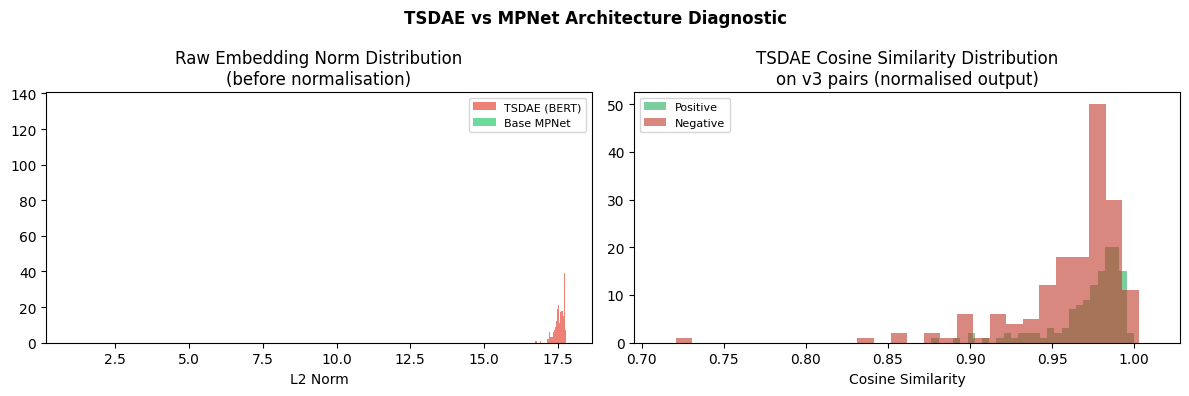

✅ Diagnostic complete


In [40]:
if not TSDAE_PATH.exists():
    print("⚠️  TSDAE not found — skipping diagnostic.")
else:
    DIAG_N = 200  # sample size for speed
    diag_texts = corpus_eval["text_clean"].sample(DIAG_N, random_state=SEED).tolist()

    # Load both
    _tsdae = SentenceTransformer(str(TSDAE_PATH), device=DEVICE)
    _base  = SentenceTransformer(BASE_MODEL,       device=DEVICE)

    # Get raw (non-normalised) embeddings
    tsdae_raw  = _tsdae.encode(diag_texts, batch_size=64, normalize_embeddings=False,
                                convert_to_numpy=True, show_progress_bar=False)
    mpnet_raw  = _base.encode( diag_texts, batch_size=64, normalize_embeddings=False,
                                convert_to_numpy=True, show_progress_bar=False)

    tsdae_norms = np.linalg.norm(tsdae_raw, axis=1)
    mpnet_norms = np.linalg.norm(mpnet_raw, axis=1)

    print(f"Embedding norm stats (n={DIAG_N}):")
    print(f"  TSDAE (BERT):  mean={tsdae_norms.mean():.3f}  std={tsdae_norms.std():.3f}  "
          f"min={tsdae_norms.min():.3f}  max={tsdae_norms.max():.3f}")
    print(f"  Base MPNet:    mean={mpnet_norms.mean():.3f}  std={mpnet_norms.std():.3f}  "
          f"min={mpnet_norms.min():.3f}  max={mpnet_norms.max():.3f}")

    # Pair-level: TSDAE after SentenceTransformer's internal normalisation
    tsdae_e1 = _tsdae.encode(v3_texts1[:300], batch_size=64, normalize_embeddings=True,
                              convert_to_numpy=True, show_progress_bar=False)
    tsdae_e2 = _tsdae.encode(v3_texts2[:300], batch_size=64, normalize_embeddings=True,
                              convert_to_numpy=True, show_progress_bar=False)
    tsdae_pair_sims = np.sum(tsdae_e1 * tsdae_e2, axis=1)
    lbl300 = np.array(v3_labels[:300], dtype=float)

    print(f"\nTSDAE pair similarity distribution (first 300 pairs):")
    print(f"  All pairs:  mean={tsdae_pair_sims.mean():.4f}  std={tsdae_pair_sims.std():.4f}  "
          f"min={tsdae_pair_sims.min():.4f}  max={tsdae_pair_sims.max():.4f}")
    print(f"  Positives:  mean={tsdae_pair_sims[lbl300==1].mean():.4f}")
    print(f"  Negatives:  mean={tsdae_pair_sims[lbl300==0].mean():.4f}")
    print(f"  Separability gap: {tsdae_pair_sims[lbl300==1].mean() - tsdae_pair_sims[lbl300==0].mean():.4f}")

    def _hist(ax, arr, n=30, **kwargs):
        """Histogram with padded range so bins always have finite width."""
        lo, hi = float(arr.min()), float(arr.max())
        pad = max((hi - lo) * 0.05, 1e-4)
        ax.hist(arr, bins=n, range=(lo - pad, hi + pad), **kwargs)

    # Distribution plot
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle("TSDAE vs MPNet Architecture Diagnostic", fontweight="bold")

    ax = axes[0]
    _hist(ax, tsdae_norms, alpha=0.7, label="TSDAE (BERT)", color="#E74C3C")
    _hist(ax, mpnet_norms, alpha=0.7, label="Base MPNet",   color="#2ECC71")
    ax.set_title("Raw Embedding Norm Distribution\n(before normalisation)")
    ax.set_xlabel("L2 Norm")
    ax.legend(fontsize=8)

    ax = axes[1]
    for lbl, col, nm in [(1, "#27AE60", "Positive"), (0, "#C0392B", "Negative")]:
        _hist(ax, tsdae_pair_sims[lbl300 == lbl], alpha=0.6, label=nm, color=col)
    ax.set_title("TSDAE Cosine Similarity Distribution\non v3 pairs (normalised output)")
    ax.set_xlabel("Cosine Similarity")
    ax.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"tsdae_diagnostic_{TS}.png", dpi=150, bbox_inches="tight")
    plt.show()

    del _tsdae, _base
    torch.cuda.empty_cache() if DEVICE == "cuda" else None
    print("✅ Diagnostic complete")


---
## Appendix — V4 Cosine Similarity Distribution Diagnostic

Does V4's fine-tuning help or hurt discrimination on **Assignment-group** pairs?  
Plots overlapping pos/neg similarity histograms for Base MPNet vs V4 Cosine on the same x-axis.  
Key metric: `gap = mean_pos_sim − mean_neg_sim`. If V4's gap < Base MPNet's gap, fine-tuning moved embeddings away from group structure.

Loading Base MPNet …


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoding v3 pairs with Base MPNet …
  done.

Loading V4 Cosine …


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  V4: LoRA adapter injected
Encoding v3 pairs with V4 Cosine …
  done.

  Model                 mean_pos  mean_neg       gap   Spearman   sep_ratio
  Base_MPNet              0.3329    0.3228   +0.0101     0.0243      0.0739
  V4_Cosine               0.3304    0.3249   +0.0054    -0.0054      0.0308

  Model                 tier                  mean_pos  mean_neg       gap
  --------------------------------------------------------------------
  Base_MPNet            hard_neg                0.3329    0.3288   +0.0041
  Base_MPNet            sap_hardest             0.3329    0.3168   +0.0161
  V4_Cosine             hard_neg                0.3304    0.3381   -0.0077
  V4_Cosine             sap_hardest             0.3304    0.3118   +0.0185

🟡 CONCLUSION: V4 gap (+0.0054) is SMALLER than Base MPNet (+0.0101).
   Fine-tuning slightly degraded group discrimination.
   → Limited benefit from current V4 for group-based retrieval.


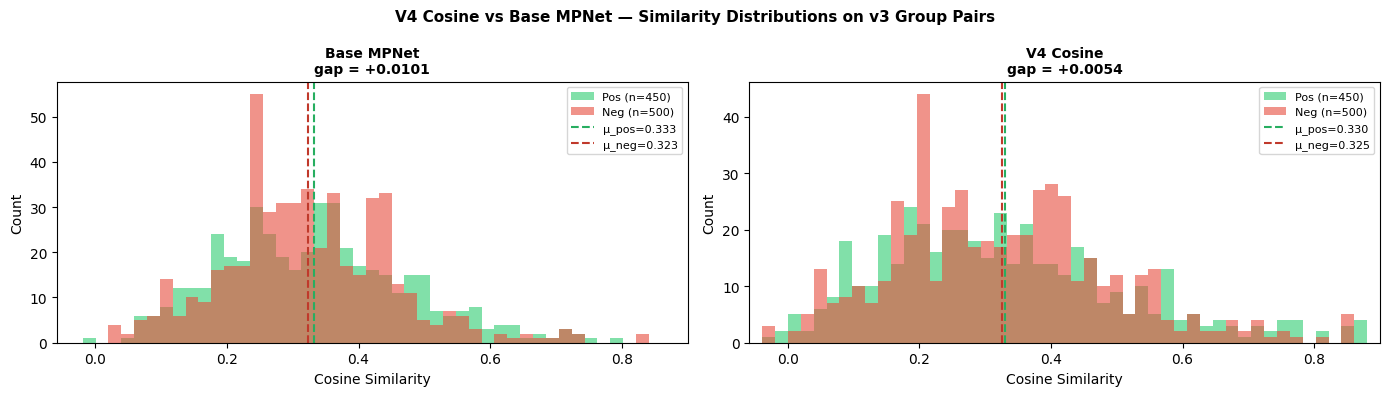

💾 Saved → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\v4_vs_base_distribution_20260225_1531.png


In [47]:
# -- V4 vs Base MPNet: similarity distribution on v3 group-based pairs --------
from peft import PeftModel as _PeftModel

def _load_base():
    m = SentenceTransformer(BASE_MODEL, device=DEVICE)
    return m

def _load_v4():
    m = SentenceTransformer(BASE_MODEL, device=DEVICE)
    if V4_MODEL_PATH.exists():
        m[0].auto_model = _PeftModel.from_pretrained(m[0].auto_model, str(V4_MODEL_PATH))
        print("  V4: LoRA adapter injected")
    else:
        print("  ⚠️  V4 path not found — using base MPNet as fallback")
    return m

print("Loading Base MPNet …")
_m_base = _load_base()
print("Encoding v3 pairs with Base MPNet …")
_e1_base = _m_base.encode(v3_texts1, batch_size=64, convert_to_numpy=True,
                           normalize_embeddings=True, show_progress_bar=False)
_e2_base = _m_base.encode(v3_texts2, batch_size=64, convert_to_numpy=True,
                           normalize_embeddings=True, show_progress_bar=False)
_sims_base = np.sum(_e1_base * _e2_base, axis=1)
del _m_base; torch.cuda.empty_cache() if DEVICE == "cuda" else None
print("  done.")

print("\nLoading V4 Cosine …")
_m_v4 = _load_v4()
print("Encoding v3 pairs with V4 Cosine …")
_e1_v4 = _m_v4.encode(v3_texts1, batch_size=64, convert_to_numpy=True,
                       normalize_embeddings=True, show_progress_bar=False)
_e2_v4 = _m_v4.encode(v3_texts2, batch_size=64, convert_to_numpy=True,
                       normalize_embeddings=True, show_progress_bar=False)
_sims_v4 = np.sum(_e1_v4 * _e2_v4, axis=1)
del _m_v4; torch.cuda.empty_cache() if DEVICE == "cuda" else None
print("  done.")

_lbl = np.array(v3_labels, dtype=float)
_tiers = np.array(v3_tiers)

# ---- Separability table -------------------------------------------------------
print("\n" + "=" * 70)
print(f"  {'Model':<20}  {'mean_pos':>8}  {'mean_neg':>8}  {'gap':>8}  {'Spearman':>9}  {'sep_ratio':>10}")
print("=" * 70)
for name, sims in [("Base_MPNet", _sims_base), ("V4_Cosine", _sims_v4)]:
    pos_s = sims[_lbl == 1]
    neg_s = sims[_lbl == 0]
    gap   = pos_s.mean() - neg_s.mean()
    sp, _ = spearmanr(sims, _lbl)
    sep   = gap / (sims.std() + 1e-9)
    print(f"  {name:<20}  {pos_s.mean():>8.4f}  {neg_s.mean():>8.4f}  {gap:>+8.4f}  {sp:>9.4f}  {sep:>10.4f}")

# Per-tier gap
print()
print(f"  {'Model':<20}  {'tier':<20}  {'mean_pos':>8}  {'mean_neg':>8}  {'gap':>8}")
print("  " + "-" * 68)
for name, sims in [("Base_MPNet", _sims_base), ("V4_Cosine", _sims_v4)]:
    pos_sims = sims[_lbl == 1]
    for neg_tier in ["hard_neg", "sap_hardest"]:
        neg_mask = _tiers == neg_tier
        neg_s = sims[neg_mask]
        gap = pos_sims.mean() - neg_s.mean()
        print(f"  {name:<20}  {neg_tier:<20}  {pos_sims.mean():>8.4f}  {neg_s.mean():>8.4f}  {gap:>+8.4f}")

print()
_gap_base = _sims_base[_lbl == 1].mean() - _sims_base[_lbl == 0].mean()
_gap_v4   = _sims_v4[_lbl == 1].mean()   - _sims_v4[_lbl == 0].mean()
if _gap_v4 <= 0:
    print("🔴 CONCLUSION: V4 has ZERO or NEGATIVE discriminative gap on group-based pairs.")
    print("   Fine-tuning on MPNet-cosine labels did NOT encode Assignment-group structure.")
    print("   → Retraining with metadata labels (assignment_group) required for v3 to improve.")
elif _gap_v4 < _gap_base:
    print(f"🟡 CONCLUSION: V4 gap ({_gap_v4:+.4f}) is SMALLER than Base MPNet ({_gap_base:+.4f}).")
    print("   Fine-tuning slightly degraded group discrimination.")
    print("   → Limited benefit from current V4 for group-based retrieval.")
else:
    print(f"🟢 CONCLUSION: V4 gap ({_gap_v4:+.4f}) > Base MPNet ({_gap_base:+.4f}).")
    print("   Fine-tuning improved Assignment-group discrimination.")

# ---- Histograms ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=False)
fig.suptitle("V4 Cosine vs Base MPNet — Similarity Distributions on v3 Group Pairs",
             fontsize=11, fontweight="bold")

_xmin = min(_sims_base.min(), _sims_v4.min()) - 0.02
_xmax = max(_sims_base.max(), _sims_v4.max()) + 0.02
_bins = np.linspace(_xmin, _xmax, 50)

for ax, name, sims in [(axes[0], "Base MPNet", _sims_base),
                        (axes[1], "V4 Cosine",  _sims_v4)]:
    pos_s = sims[_lbl == 1]
    neg_s = sims[_lbl == 0]
    ax.hist(pos_s, bins=_bins, alpha=0.60, color="#2ECC71", label=f"Pos (n={len(pos_s)})")
    ax.hist(neg_s, bins=_bins, alpha=0.60, color="#E74C3C", label=f"Neg (n={len(neg_s)})")
    ax.axvline(pos_s.mean(), color="#27AE60", linestyle="--", linewidth=1.5,
               label=f"μ_pos={pos_s.mean():.3f}")
    ax.axvline(neg_s.mean(), color="#C0392B", linestyle="--", linewidth=1.5,
               label=f"μ_neg={neg_s.mean():.3f}")
    gap = pos_s.mean() - neg_s.mean()
    ax.set_title(f"{name}\ngap = {gap:+.4f}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Cosine Similarity")
    ax.set_ylabel("Count")
    ax.set_xlim(_xmin, _xmax)
    ax.legend(fontsize=8)

plt.tight_layout()
_diag_path = OUTPUT_DIR / f"v4_vs_base_distribution_{TS}.png"
plt.savefig(_diag_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"💾 Saved → {_diag_path}")

---
## Step 10 — Side-by-Side Results & Verification Gates

In [41]:
# -- Retrieval results ---------------------------------------------------------
ret_df = pd.DataFrame(ALL_RET).T.sort_values("NDCG@10", ascending=False)
print("=" * 70)
print("  RETRIEVAL — v3 benchmark (same Assignment group = relevant)")
print("=" * 70)
print(ret_df.round(4).to_string())

# Gate 1 (re-check from latest data)
ndcg_tfidf_final = ALL_RET.get("TF-IDF_BM25", {}).get("NDCG@10", 1.0)
print(f"\n🔎 GATE 1: TF-IDF NDCG@10 = {ndcg_tfidf_final:.4f}  (target ≤ 0.65)  "
      f"{'✅' if ndcg_tfidf_final <= 0.65 else '❌'}")

# -- Pair results --------------------------------------------------------------
pair_cols = ["Spearman", "ROC_AUC", "F1_test", "Acc_test", "Threshold"]
pair_df = pd.DataFrame(ALL_PAIRS).T[pair_cols].sort_values("Spearman", ascending=False)
print("\n" + "=" * 70)
print("  PAIR-LEVEL — v3 semantic_test_pairs_v3.json (metadata labels)")
print("=" * 70)
print(pair_df.round(4).to_string())

# Gate 2
sp_tfidf = ALL_PAIRS.get("TF-IDF_BM25", {}).get("Spearman", 1.0)
print(f"\n🔎 GATE 2: TF-IDF Spearman = {sp_tfidf:.4f}  (target ≤ 0.65)  "
      f"{'✅' if sp_tfidf <= 0.65 else '❌'}")

# Gate 3
v4_sp   = ALL_PAIRS.get("V4_Cosine",  {}).get("Spearman", 0)
base_sp = ALL_PAIRS.get("Base_MPNet", {}).get("Spearman", 0)
delta   = abs(v4_sp - base_sp)
print(f"\n🔎 GATE 3: V4 vs Base MPNet Spearman Δ = {delta:.4f}  (target ≥ 0.01)  "
      f"{'✅' if delta >= 0.01 else '⚠️  too small — benchmark may need further hardening'}")

# v2 vs v3 regression comparison
print("\n" + "=" * 70)
print("  REGRESSION — v2 vs v3 pair benchmark comparison")
print("=" * 70)
v2_spearman = {"TF-IDF_BM25": 0.8051, "Base_MPNet": 0.8333, "V4_Cosine": 0.8382,
               "ICT": 0.7972, "TSDAE": 0.7126, "GPL": 0.4064}
for model in ["TF-IDF_BM25", "Base_MPNet", "V4_Cosine", "ICT", "TSDAE", "GPL"]:
    v2_sp = v2_spearman.get(model, None)
    v3_sp = ALL_PAIRS.get(model, {}).get("Spearman", None)
    if v2_sp and v3_sp:
        delta = v3_sp - v2_sp
        arrow = "↓" if delta < -0.02 else "↑" if delta > 0.02 else "→"
        print(f"  {model:20s}  v2={v2_sp:.4f}  v3={v3_sp:.4f}  Δ={delta:+.4f} {arrow}")

  RETRIEVAL — v3 benchmark (same Assignment group = relevant)
             NDCG@10  MRR@10  Recall@1  Recall@5  Recall@10
ICT           0.4014  0.5851    0.0023    0.0091     0.0152
Base_MPNet    0.3828  0.5843    0.0024    0.0096     0.0150
TF-IDF_BM25   0.3791  0.6017    0.0024    0.0088     0.0146
V4_Cosine     0.3645  0.5711    0.0025    0.0090     0.0142
TSDAE         0.2146  0.3680    0.0009    0.0029     0.0046
GPL           0.2008  0.3371    0.0006    0.0023     0.0042

🔎 GATE 1: TF-IDF NDCG@10 = 0.3791  (target ≤ 0.65)  ✅

  PAIR-LEVEL — v3 semantic_test_pairs_v3.json (metadata labels)
             Spearman  ROC_AUC  F1_test  Acc_test  Threshold
TSDAE          0.2096   0.6212   0.6548    0.5145     0.9071
TF-IDF_BM25    0.1129   0.5652   0.6076    0.4868     0.0027
ICT            0.0662   0.5382   0.6422    0.5000    -0.0930
GPL            0.0551   0.5318   0.6434    0.4763    -0.9972
Base_MPNet     0.0243   0.5140   0.6434    0.4763     0.0428
V4_Cosine     -0.0054   0.4969  

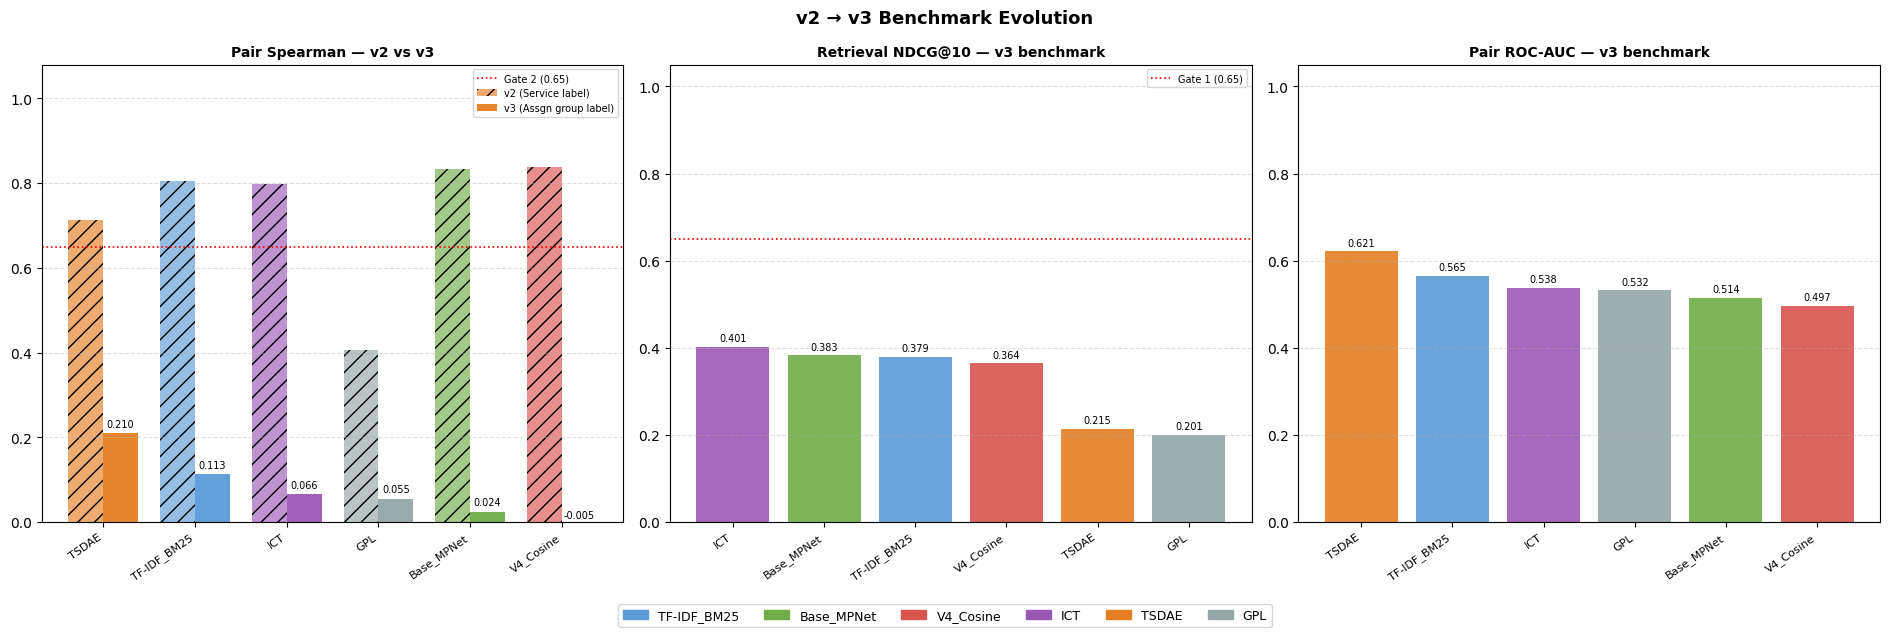

💾 Saved → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\v2_vs_v3_comparison_20260225_1531.png


In [42]:
# -- Comparison bar charts (v2 Spearman vs v3 Spearman + retrieval) ------------
palette = {
    "TF-IDF_BM25": "#5B9BD5",
    "Base_MPNet":  "#70AD47",
    "V4_Cosine":   "#D9534F",
    "ICT":         "#9B59B6",
    "TSDAE":       "#E67E22",
    "GPL":         "#95A5A6",
}

v2_spearman = {"TF-IDF_BM25": 0.8051, "Base_MPNet": 0.8333, "V4_Cosine": 0.8382,
               "ICT": 0.7972, "TSDAE": 0.7126, "GPL": 0.4064}

models_order = list(pair_df.index)

def bar_group(ax, model_names, v2_vals, v3_vals, title):
    x  = np.arange(len(model_names))
    w  = 0.38
    b1 = ax.bar(x - w/2, v2_vals, w, label="v2 (Service label)", alpha=0.65,
                color=[palette.get(m, "#aaa") for m in model_names], hatch="//")
    b2 = ax.bar(x + w/2, v3_vals, w, label="v3 (Assgn group label)", alpha=0.95,
                color=[palette.get(m, "#aaa") for m in model_names])
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, rotation=35, ha="right", fontsize=8)
    ax.set_ylim(0, 1.08)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(fontsize=8)
    ax.set_title(title, fontsize=10, fontweight="bold")
    for bar, v in [(b2, v3_vals)]:
        for b, val in zip(bar, v):
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                    f"{val:.3f}", ha="center", va="bottom", fontsize=7)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
fig.suptitle("v2 → v3 Benchmark Evolution", fontsize=13, fontweight="bold")

# Spearman v2 vs v3
v2_sp_vals = [v2_spearman.get(m, 0) for m in models_order]
v3_sp_vals = [ALL_PAIRS.get(m, {}).get("Spearman", 0) for m in models_order]
bar_group(axes[0], models_order, v2_sp_vals, v3_sp_vals, "Pair Spearman — v2 vs v3")
axes[0].axhline(0.65, color="red", linestyle=":", linewidth=1.2, label="Gate 2 (0.65)")
axes[0].legend(fontsize=7)

# NDCG@10 retrieval v3
ret_names = list(ret_df.index)
ret_ndcg  = [float(ret_df.loc[m, "NDCG@10"]) for m in ret_names]
ret_mrr   = [float(ret_df.loc[m, "MRR@10"])  for m in ret_names]
x = np.arange(len(ret_names))
bars = axes[1].bar(x, ret_ndcg, color=[palette.get(m, "#aaa") for m in ret_names], alpha=0.9)
axes[1].axhline(0.65, color="red", linestyle=":", linewidth=1.2, label="Gate 1 (0.65)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(ret_names, rotation=35, ha="right", fontsize=8)
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Retrieval NDCG@10 — v3 benchmark", fontsize=10, fontweight="bold")
axes[1].legend(fontsize=7)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
for bar, v in zip(bars, ret_ndcg):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008,
                 f"{v:.3f}", ha="center", va="bottom", fontsize=7)

# ROC-AUC v3 pairs
roc_vals = [ALL_PAIRS.get(m, {}).get("ROC_AUC", 0) for m in models_order]
bars2 = axes[2].bar(x[:len(models_order)], roc_vals,
                    color=[palette.get(m, "#aaa") for m in models_order], alpha=0.9)
axes[2].set_xticks(np.arange(len(models_order)))
axes[2].set_xticklabels(models_order, rotation=35, ha="right", fontsize=8)
axes[2].set_ylim(0, 1.05)
axes[2].set_title("Pair ROC-AUC — v3 benchmark", fontsize=10, fontweight="bold")
axes[2].grid(axis="y", linestyle="--", alpha=0.4)
for bar, v in zip(bars2, roc_vals):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008,
                 f"{v:.3f}", ha="center", va="bottom", fontsize=7)

patches = [mpatches.Patch(color=c, label=m) for m, c in palette.items()]
fig.legend(handles=patches, loc="lower center", ncol=6,
           bbox_to_anchor=(0.5, -0.06), fontsize=9)

plt.tight_layout()
fig_path = OUTPUT_DIR / f"v2_vs_v3_comparison_{TS}.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"💾 Saved → {fig_path}")

In [45]:
# -- Per-tier Spearman breakdown -----------------------------------------------
# Keys: Spearman_vs_hard_neg, Spearman_vs_sap_hardest (pos+neg combined slice)
tier_rows = []
for model, res in ALL_PAIRS.items():
    row = {
        "Model":          model,
        "Overall":        res.get("Spearman", None),
        "vs_hard_neg":    res.get("Spearman_vs_hard_neg", None),
        "vs_sap_hardest": res.get("Spearman_vs_sap_hardest", None),
    }
    tier_rows.append(row)

tier_df = pd.DataFrame(tier_rows).set_index("Model")
has_tier_data = tier_df[["vs_hard_neg", "vs_sap_hardest"]].notna().any().any()
print("📊 Per-tier Spearman (positive pairs vs each negative tier):")
print("   Combined-slice: positives + one neg tier, Spearman(sim, label)")
print(f"   {'⚠️  All NaN — models may need to be re-evaluated with updated eval_pairs' if not has_tier_data else ''}")
print(tier_df.round(4).to_string())
tier_df.to_csv(OUTPUT_DIR / f"tier_breakdown_v3_{TS}.csv")

📊 Per-tier Spearman (positive pairs vs each negative tier):
   Combined-slice: positives + one neg tier, Spearman(sim, label)
   
             Overall  vs_hard_neg  vs_sap_hardest
Model                                            
TF-IDF_BM25   0.1129       0.0671          0.1496
Base_MPNet    0.0243       0.0135          0.0331
V4_Cosine    -0.0054      -0.0358          0.0255
ICT           0.0662       0.0563          0.0706
TSDAE         0.2096       0.1677          0.2345
GPL           0.0551      -0.0052          0.1109


In [46]:
# -- Save all results ----------------------------------------------------------
bundle = {
    "timestamp": TS,
    "retrieval_v3": ALL_RET,
    "pairs_v3":     ALL_PAIRS,
    "gates": {
        "gate1_tfidf_ndcg": {"value": ndcg_tfidf_final, "threshold": 0.65,
                              "pass": ndcg_tfidf_final <= 0.65},
        "gate2_tfidf_spearman": {"value": sp_tfidf, "threshold": 0.65,
                                  "pass": sp_tfidf <= 0.65},
        "gate3_v4_base_delta": {"value": delta, "threshold": 0.01,
                                 "pass": delta >= 0.01},
    },
    "v3_pair_stats": {
        "total": len(all_pairs_v3),
        "positives": len(pos_pairs),
        "hard_neg": len(hard_neg_pairs),
        "sap_hardest": len(sap_neg_pairs),
        "tfidf_gate_pos": MAX_TF_POS,
        "tfidf_gate_hard_neg": MAX_TF_HARD_NEG,
        "tfidf_gate_sap": MAX_TF_SAP_NEG,
        "pos_mean_tfidf": round(float(np.mean([p["tfidf_sim"] for p in pos_pairs])), 4),
    },
    "retrieval_stats": {
        "n_queries": len(queries_v3),
        "corpus_size": len(corpus_eval),
        "avg_relevant_per_query": round(avg_rel, 1),
        "pct_corpus_relevant": round(pct_corpus, 2),
    },
    "v2_reference_spearman": v2_spearman,
}

results_path = OUTPUT_DIR / f"eval_v3_results_{TS}.json"
with open(results_path, "w", encoding="utf-8") as f:
    json.dump(bundle, f, indent=2, default=str)
print(f"💾 Results → {results_path}")

ret_df.to_csv(OUTPUT_DIR / f"retrieval_v3_{TS}.csv")
pair_df.to_csv(OUTPUT_DIR / f"pairs_v3_{TS}.csv")
tier_df.to_csv(OUTPUT_DIR / f"tier_breakdown_v3_{TS}.csv")
print(f"💾 CSVs → {OUTPUT_DIR}")

💾 Results → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\eval_v3_results_20260225_1531.json
💾 CSVs → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results


---
## Interpretation Guide

### Gate checklist

| Gate | Condition | If PASS | If FAIL |
|------|-----------|---------|--------|
| **1** TF-IDF NDCG@10 ≤ 0.65 | same-group qrels are not lexically trivial | Retrieval rank ordering is meaningful | Tighten to same group + cross-vendor (CAPG vs PISCAP) as qrels |
| **2** TF-IDF Spearman ≤ 0.65 | pair benchmark tests semantic signal | Pair ordering is meaningful | Further tighten TF-IDF gate on positives to ≤ 0.15 |
| **3** V4/MPNet Δ ≥ 0.01 | benchmark is sensitive enough | Fine-grained model comparison is valid | Benchmark is too noisy — add 500 more pairs or rerun with different seed |

### Interpreting per-tier Spearman

- `standard_pos`: model cleanly separating same-group docs from their hard negatives
- `hard_neg` (same-service, diff-group): model understands cross-functional SAP differences
- `sap_hardest` (same-group, diff-offering): the toughest test — fine-grained within-SAP topic discrimination

**Expected ordering if a model is genuinely better**: higher `sap_hardest` Spearman is the best single indicator of semantic quality beyond keyword matching.

### What ICT's retrieval advantage means

ICT was trained with sentence→document retrieval objectives (MultipleNegativesRankingLoss on IVC pairs). The v3 retrieval benchmark uses the same structure. If ICT outperforms V4 here, it is **task-protocol leakage**, not evidence of better general semantic quality. Compare only on the pair-level benchmarks for a protocol-fair model comparison.

### Next steps based on outcomes

| Outcome | Action |
|---------|--------|
| V4 > Base MPNet on v3 pairs | LoRA training is working — proceed to fix curriculum pair imbalance (1:1 ratio) and retrain for potential further gains |
| Base MPNet ≥ V4 on v3 pairs | Investigate curriculum pair quality — run `validate_pairs_finetune_mpnet.ipynb`, check if positives have TF-IDF cosine > 0.25 (lexical shortcut) |
| TSDAE diagnostic: raw norms very different from MPNet | BERT base is incompatible with MPNet-centric curriculum; TSDAE needs full retrain on MPNet base |
| GPL Spearman still < 0.5 | Apply sigmoid to CE scores before MarginMSE, increase training steps to 10K |
| Any gate FAIL | Add `same_group + cross_vendor (CAPG vs PISCAP)` as an even harder relevance tier |